# Question 1 - Finding the 2 Nearest Neighbors in the Iris Dataset

In [ ]:
import seaborn as sns
import pandas as pd
from sklearn.neighbors import NearestNeighbors

iris = sns.load_dataset("iris")
df = iris.copy()
X = df.drop("species", axis = 1)

new_observation = pd.DataFrame([[ 1, 1, 1, 1]], columns = X.columns)

model = NearestNeighbors(n_neighbors = 2)
model.fit(X)

distances, indices = model.kneighbors(new_observation)#Yeni gözleme en yakın komşuların uzaklıklarını ve indekslerini döndürür.
print("Distances:", distances)
print("Indices:", indices)
print("Nearest observations:")
print(X.iloc[indices[0]])

Distances: [[3.81051178 3.96358424]]
Indices: [[41 13]]
Nearest observations:
    sepal_length  sepal_width  petal_length  petal_width
41           4.5          2.3           1.3          0.3
13           4.3          3.0           1.1          0.1


# Question 2 - Predicting Classes Using 5 Nearest Neighbors (KNN Classification)

In [ ]:
import seaborn as sns
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

iris = sns.load_dataset("iris")
df = iris.copy()
X = df.drop("species", axis = 1)
y = df["species"]
new_observations = pd.DataFrame([[0.75, 0.75, 0.75, 0.75],[1, 1, 1, 1]], columns = X.columns)   
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X,y)

prediction = model.predict(new_observations)

distances, indices = model.kneighbors(new_observation)#Yeni gözleme en yakın komşuların uzaklıklarını ve indekslerini döndürür.
print("Predicted classes:", prediction)
print("Neighbor indices:")
print(indices)
print("Neighbor classes:")
print(y.iloc[indices[0]].values)
print(y.iloc[indices[1]].values)

Predicted classes: ['setosa' 'setosa']
Neighbor indices:
[[41 13  8 38 42]
 [41 13  8 38 42]]
Neighbor classes:
<StringArray>
['setosa', 'setosa', 'setosa', 'setosa', 'setosa']
Length: 5, dtype: str
<StringArray>
['setosa', 'setosa', 'setosa', 'setosa', 'setosa']
Length: 5, dtype: str


# Question 3 – Selecting the Best K Value for K-Nearest Neighbors

Best k for prediction 1
Max accuraccy score:  1.0


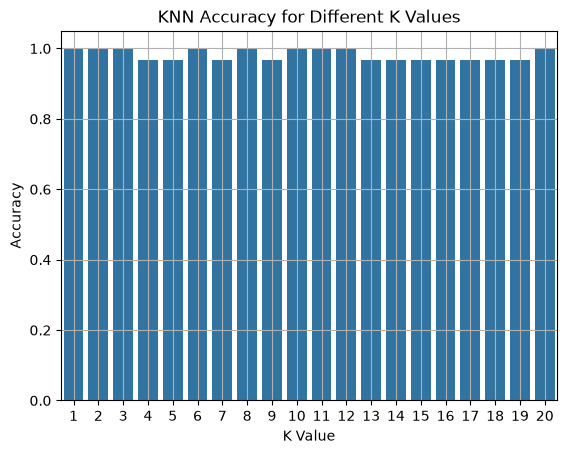

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

iris = sns.load_dataset("iris")
df = iris.copy()

X = df.drop("species", axis=1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=61, stratify=y)

k_values = range(1,21)
accuracies = []

for i in k_values:
    model = KNeighborsClassifier(n_neighbors=i)
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

best_k = k_values[accuracies.index(max(accuracies))]
best_k = print("Best k for prediction", best_k)
max_acc = print("Max accuraccy score: ", max(accuracies))

sns.barplot(x=k_values, y=accuracies)
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.grid()
plt.show()

# Question 4 – Gaussian Naive Bayes Classification and Probability Calibration

In [57]:
import seaborn as sns
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV

iris = sns.load_dataset("iris")
df = iris.copy()
X = df.drop("species", axis = 1)
y = df["species"]
new_observation = pd.DataFrame([[ 4, 4, 4, 0.4]], columns = X.columns)   

model = GaussianNB()#Sürekli sayısal özelliklerin her sınıf içinde normal dağılıma uyduğunu varsayan Naive Bayes modelidir.
model.fit(X,y)

prediction = model.predict(new_observation)
probabilty = model.predict_proba(new_observation)

print("Classes: ", model.classes_)
print("Prior Probabilities:", model.class_prior_)

print("Predicted Class:", prediction)
print("Class Probabilities:", probabilty)

#Kalibrasyonun amacı tahmin olasılıklarını daha güvenilir hale getirmektir.
calibrated_model = CalibratedClassifierCV(
    GaussianNB(),
    method="sigmoid",#Sigmoid tabanlı kalibrasyon kullanır.
    cv=5#Kalibrasyon sırasında 5-fold cross-validation uygular.
)

calibrated_model.fit(X,y)

calibrated_prediction = calibrated_model.predict(new_observation)
calibrated_probabilty = calibrated_model.predict_proba(new_observation)


print("Predicted Class:", calibrated_prediction)
print("Calibrated Probabilities:", calibrated_probabilty)


Classes:  ['setosa' 'versicolor' 'virginica']
Prior Probabilities: [0.33333333 0.33333333 0.33333333]
Predicted Class: ['versicolor']
Class Probabilities: [[1.34715602e-38 9.99949727e-01 5.02727760e-05]]
Predicted Class: ['versicolor']
Calibrated Probabilities: [[0.04543623 0.89245411 0.06210966]]


# Question 5 – Gaussian Naive Bayes with Custom Prior Probabilities

In [ ]:
import seaborn as sns
import pandas as pd
from sklearn.naive_bayes import GaussianNB

iris = sns.load_dataset("iris")
df = iris.copy()
X = df.drop("species", axis = 1)
y = df["species"]
new_observation = pd.DataFrame([[ 4, 4, 4, 0.4]], columns = X.columns)   

'''
Önceki soruda GaussianNB() kullanırken sınıfların baştaki prior olasılıkları veri setinden otomatik hesaplanıyordu.
Iris veri setinde her sınıftan 50 gözlem olduğu için olasılıkları 0.33'dür her bir gözlemin normalde en başta. Kendiğimiz 
verdiğimiz değerler ile olasılıkları değiştiriyoruz
'''
model = GaussianNB(priors=[0.25, 0.25, 0.5])
model.fit(X,y)

prediction = model.predict(new_observation)
probabilty = model.predict_proba(new_observation)

print("Classes:", model.classes_)
print("Prior Probabilities:", model.class_prior_)
print("Predicted Class:", prediction)
print("Class Probabilities:", probabilty)

Classes: ['setosa' 'versicolor' 'virginica']
Prior Probabilities: [0.25 0.25 0.5 ]
Predicted Class: ['versicolor']
Class Probabilities: [[1.34708830e-38 9.99899460e-01 1.00540498e-04]]


# Question 6 – Bernoulli Naive Bayes Classification.

In [ ]:
import numpy as np
from sklearn.naive_bayes import BernoulliNB #Binary (0 ve 1) özelliklerle çalışan Naive Bayes sınıflandırıcısıdır.

X = np.random.randint(0,2, size=(6,3))
y = np.array([1,0,0,1,0,1])

model = BernoulliNB()
model.fit(X,y)

new_observation = [[1,0,1]]

prediction = model.predict(new_observation)
probabilty = model.predict_proba(new_observation)

print("Classes:", model.classes_)
print("Predicted Class:", prediction)
print("Class Probabilities:", probabilty)

Classes: [0 1]
Predicted Class: [0]
Class Probabilities: [[0.6 0.4]]
